# Thermocouple Display Digit Classifier
A separate notebook for training a digit classifier. It does not modify your existing notebook.

Workflow:
1. Load your video and choose frames after the display stabilizes.
2. Manually crop and label individual digits.
3. Train an SVM classifier using HOG image features.
4. Test predictions, then later build a full temperature-reading loop.

**Important:** the model learns from examples you label. Start with 20–50 examples per digit if possible, including different frames and lighting conditions. This first version classifies individual digits, not decimal points or minus signs.

## 1. Install and import libraries
Run the install cell in the same Python environment/kernel you use for OpenCV.

In [3]:
%pip install opencv-python matplotlib numpy scikit-learn scikit-image joblib pandas

Note: you may need to restart the kernel to use updated packages.


In [4]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import joblib
import pandas as pd
from skimage.feature import hog
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score

## 2. Set your video path and inspect a frame

The path below matches the one used in your earlier project. Change it if your video is somewhere else. We start at 3 seconds because you observed that the display stabilizes around then.

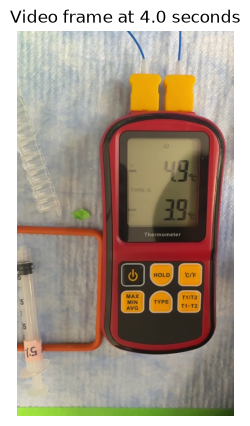

In [ ]:
VIDEO_PATH = Path(r"C:/Users/tarin/thermocouple-reader/videos/IMG_3045.MOV")
START_SECONDS = 4.0
ROTATION = 0

DATA_DIR = Path("digit_dataset")
DATA_DIR.mkdir(exist_ok=True)
for digit in range(10):
    (DATA_DIR / str(digit)).mkdir(parents=True, exist_ok=True)

def rotate_frame(frame, angle=ROTATION_ANGLE):
    if angle == 0:
        return frame

    height, width = frame.shape[:2]
    center = (width / 2, height / 2)

    rotation_matrix = cv2.getRotationMatrix2D(
        center, angle, 1.0
    )

    return cv2.warpAffine(
        frame,
        rotation_matrix,
        (width, height),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REPLICATE
    )

def read_frame_at(seconds):
    cap = cv2.VideoCapture(str(VIDEO_PATH))
    if not cap.isOpened():
        raise FileNotFoundError(f"Could not open video: {VIDEO_PATH}\nUpdate VIDEO_PATH to the correct location.")
    cap.set(cv2.CAP_PROP_POS_MSEC, float(seconds) * 1000)
    ok, frame = cap.read()
    cap.release()
    if not ok:
        raise ValueError(f"Could not read a frame at {seconds} seconds.")
    frame = rotate_frame(frame)
    return frame

frame = read_frame_at(START_SECONDS)
plt.figure(figsize=(14, 5))
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title(f"Video frame at {START_SECONDS:.1f} seconds")
plt.axis("off");

## 3. Collect labeled examples

Run the collection function when you're ready. For each sample:
- Enter a timestamp in seconds (e.g. `3.0`, `4.0`, `5.0`).
- A window opens. Drag a rectangle around **one digit only** and press Enter/Space to accept. Press `c` to cancel.
- Type the digit label `0`–`9`.
- Repeat for different timestamps and both display regions if their digits look similar.

Select the whole digit, with as little surrounding display/background as possible. Label what the display actually shows, not what a model predicts.

In [15]:

def collect_digit_samples():
    DISPLAY_SCALE = 0.5  # 50% size; use 0.35 to zoom out further

    print("Enter timestamps one at a time. Leave blank to stop.")

    while True:
        entry = input("Timestamp in seconds (blank to stop): ").strip()
        if not entry:
            break

        try:
            seconds = float(entry)
            image = read_frame_at(seconds)

            if image is None:
                print("Could not load frame.")
                continue

        except Exception as exc:
            print("Could not load frame:", exc)
            continue

        # Create a smaller preview for selecting the digit
        small_image = cv2.resize(
            image,
            None,
            fx=DISPLAY_SCALE,
            fy=DISPLAY_SCALE,
            interpolation=cv2.INTER_AREA
        )

        preview = small_image.copy()

        cv2.putText(
            preview,
            f"t={seconds:.2f}s: select ONE digit; press c to cancel",
            (10, 25),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            (0, 255, 0),
            1
        )

        x, y, w, h = map(
            int,
            cv2.selectROI(
                "Select one digit - zoomed out",
                preview,
                showCrosshair=True,
                fromCenter=False
            )
        )
        cv2.destroyAllWindows()

        if w == 0 or h == 0:
            print("Selection cancelled.")
            continue

        # Convert selection coordinates back to original image size
        x = round(x / DISPLAY_SCALE)
        y = round(y / DISPLAY_SCALE)
        w = round(w / DISPLAY_SCALE)
        h = round(h / DISPLAY_SCALE)

        # Crop from the ORIGINAL image, not the resized preview
        digit_crop = image[y:y+h, x:x+w]

        label = input("What digit is this? Enter 0-9: ").strip()

        if label not in [str(i) for i in range(10)]:
            print("Invalid label; sample not saved.")
            continue

        normalized = normalize_digit_crop(digit_crop)

        folder = DATA_DIR / label
        folder.mkdir(parents=True, exist_ok=True)

        # Use the next available filename to avoid overwriting samples
        existing_files = list(folder.glob("digit_*.png"))
        existing_numbers = []

        for file in existing_files:
            try:
                existing_numbers.append(int(file.stem.split("_")[-1]))
            except ValueError:
                pass

        next_number = max(existing_numbers, default=-1) + 1
        output_path = folder / f"digit_{next_number:04d}.png"

        cv2.imwrite(str(output_path), normalized)
        print(f"Saved {label} to {output_path}")

        plt.figure(figsize=(3, 4))
        plt.imshow(normalized, cmap="gray", vmin=0, vmax=255)
        plt.title(f"Saved label: {label}")
        plt.axis("off")
        plt.show()


Enter timestamps one at a time. Leave blank to stop.
Selection cancelled.
Selection cancelled.
Selection cancelled.
Selection cancelled.
Selection cancelled.
Saved 8 to digit_dataset\8\digit_0017.png


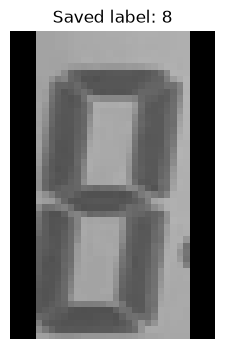

Invalid label; sample not saved.
Saved 4 to digit_dataset\4\digit_0015.png


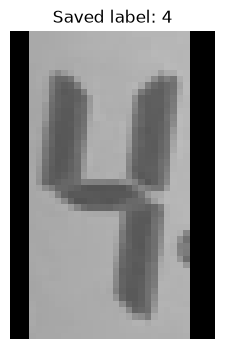

Saved 8 to digit_dataset\8\digit_0018.png


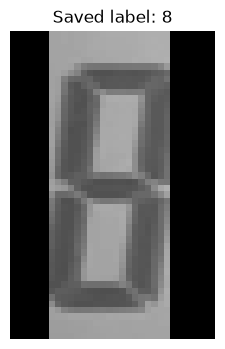

Saved 6 to digit_dataset\6\digit_0011.png


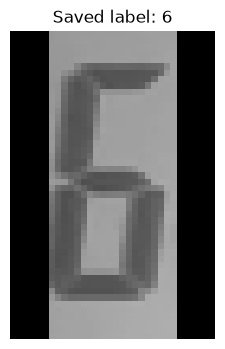

Saved 0 to digit_dataset\0\digit_0014.png


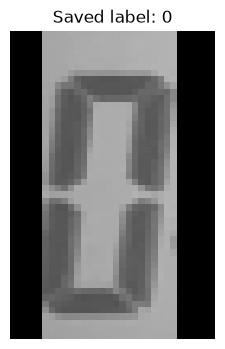

In [99]:
# Run function to add to existing data set
collect_digit_samples()

### Collect enough examples
Run the cell above, remove the `#` from `collect_digit_samples()` at the bottom, and run it. Collect a range of digits across different frames. You can run it again later to add more examples.

## 4. Check the dataset

In [100]:
def show_dataset_counts():
    counts = {}
    for digit in range(10):
        counts[str(digit)] = len(list((DATA_DIR / str(digit)).glob("*.png")))
    for digit, count in counts.items():
        print(f"{digit}: {count} sample(s)")
    return counts

counts = show_dataset_counts()

0: 15 sample(s)
1: 12 sample(s)
2: 14 sample(s)
3: 18 sample(s)
4: 16 sample(s)
5: 18 sample(s)
6: 12 sample(s)
7: 17 sample(s)
8: 19 sample(s)
9: 14 sample(s)


## 5. Train the classifier

HOG features describe edges/strokes, and an SVM learns to distinguish the digit examples. This is a lightweight baseline that runs on a normal laptop.

Total samples: 155
Samples by label: {np.str_('0'): np.int64(15), np.str_('1'): np.int64(12), np.str_('2'): np.int64(14), np.str_('3'): np.int64(18), np.str_('4'): np.int64(16), np.str_('5'): np.int64(18), np.str_('6'): np.int64(12), np.str_('7'): np.int64(17), np.str_('8'): np.int64(19), np.str_('9'): np.int64(14)}
Test accuracy: 0.949
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         4
           1       1.00      1.00      1.00         3
           2       0.60      1.00      0.75         3
           3       1.00      0.80      0.89         5
           4       1.00      1.00      1.00         4
           5       1.00      1.00      1.00         5
           6       1.00      1.00      1.00         3
           7       1.00      1.00      1.00         4
           8       1.00      0.80      0.89         5
           9       1.00      1.00      1.00         3

    accuracy                           0.95        39
   macro av

c:\Users\tarin\anaconda3\envs\thermo-ml\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


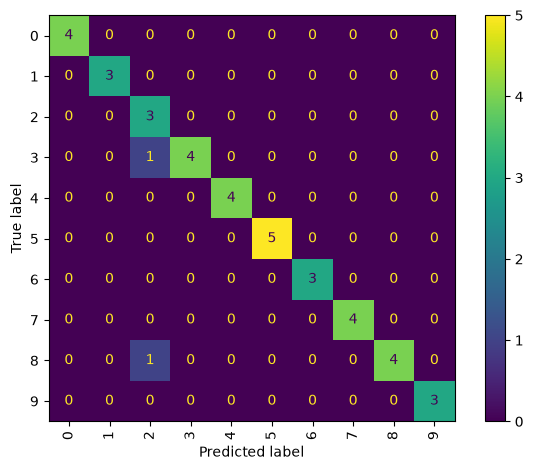

Saved model to thermocouple_digit_model.joblib


In [101]:
def image_to_features(gray_image):
    gray_image = cv2.resize(gray_image, (32, 48), interpolation=cv2.INTER_AREA)
    return hog(gray_image, orientations=9, pixels_per_cell=(8, 8),
               cells_per_block=(2, 2), block_norm="L2-Hys")

def load_labeled_dataset():
    features, labels = [], []
    for digit in range(10):
        for image_path in sorted((DATA_DIR / str(digit)).glob("*.png")):
            image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
            if image is not None:
                features.append(image_to_features(image))
                labels.append(str(digit))
    if not features:
        raise ValueError("No samples found. Collect labeled digit examples first.")
    return np.asarray(features), np.asarray(labels)

X, y = load_labeled_dataset()
unique, counts = np.unique(y, return_counts=True)
print("Total samples:", len(y))
print("Samples by label:", dict(zip(unique, counts)))
if len(unique) < 2:
    raise ValueError("Collect examples from at least two different digits before training.")

stratify_labels = y if all(np.sum(y == label) >= 2 for label in unique) else None
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=stratify_labels
)
model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=42)
)
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, predictions):.3f}")
print(classification_report(y_test, predictions, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, xticks_rotation="vertical")
plt.tight_layout()
plt.show()
joblib.dump(model, "thermocouple_digit_model.joblib")
print("Saved model to thermocouple_digit_model.joblib")

## 6. Test a single digit crop

Choose a digit from a frame to see what the model predicts. The confidence value is a model score, not a guarantee of correctness.

Predicted digit: 2 | model score: 24.3%


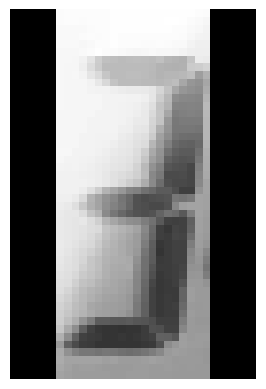

In [86]:
def predict_digit_crop(crop, model=model):
    normalized = normalize_digit_crop(crop)
    features = image_to_features(normalized).reshape(1, -1)
    probabilities = model.predict_proba(features)[0]
    best_index = int(np.argmax(probabilities))
    return model.classes_[best_index], float(probabilities[best_index]), normalized

# Uncomment and run these lines to test a digit at 4 seconds:
test_frame = read_frame_at(2.0)
x, y, w, h = map(int, cv2.selectROI("Select test digit", test_frame, showCrosshair=True))
cv2.destroyAllWindows()
test_crop = test_frame[y:y+h, x:x+w]
label, score, normalized = predict_digit_crop(test_crop)
print(f"Predicted digit: {label} | model score: {score:.1%}")
plt.imshow(normalized, cmap="gray"); plt.axis("off");

## 7. Later: turn digit predictions into temperatures

Once single-digit classification is reliable, the next stage is to define fixed crop locations for each digit in each thermocouple display, classify each digit, detect the decimal point/minus sign separately, and combine the characters into a temperature. Then we can process video frames at regular intervals and save timestamp plus both temperatures to CSV.

Don't build the full video-reading loop until the classifier performs well on examples it has not trained on. If some digits are often confused, collect more examples of those digits.

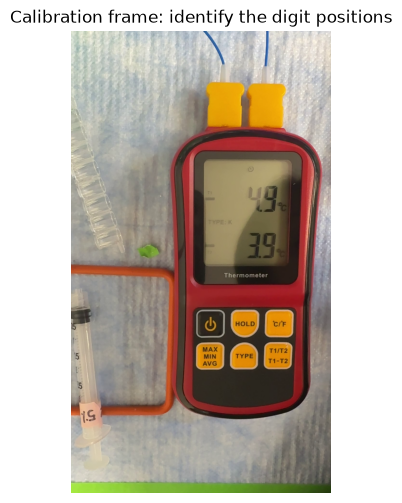

In [95]:
CALIBRATION_TIME = 4.0

calibration_frame = read_frame_at(CALIBRATION_TIME)

plt.figure(figsize=(14, 6))
plt.imshow(cv2.cvtColor(calibration_frame, cv2.COLOR_BGR2RGB))
plt.title("Calibration frame: identify the digit positions")
plt.axis("off");

In [96]:

# SECTION 9: Select digit boxes on a resized frame

digit_boxes = {"T1": [], "T2": []}

# Shrink the image for easier viewing
DISPLAY_SCALE = 0.5  # 50% size; try 0.35 if it is still too large

small_frame = cv2.resize(
    calibration_frame,
    None,
    fx=DISPLAY_SCALE,
    fy=DISPLAY_SCALE,
    interpolation=cv2.INTER_AREA
)

for display_name in ["T1", "T2"]:
    count = int(input(
        f"How many digit boxes for {display_name}? "
    ))

    for i in range(count):
        print(f"{display_name}: select digit {i + 1}")

        x, y, w, h = map(
            int,
            cv2.selectROI(
                f"{display_name} - digit {i + 1}",
                small_frame,
                showCrosshair=True,
                fromCenter=False
            )
        )
        cv2.destroyAllWindows()

        if w == 0 or h == 0:
            raise ValueError(
                "Selection cancelled. Rerun Section 9."
            )

        # Convert resized-frame coordinates to original coordinates
        x = round(x / DISPLAY_SCALE)
        y = round(y / DISPLAY_SCALE)
        w = round(w / DISPLAY_SCALE)
        h = round(h / DISPLAY_SCALE)

        digit_boxes[display_name].append((x, y, w, h))

print("Saved boxes in ORIGINAL frame coordinates:")
print(digit_boxes)


T1: select digit 1
T1: select digit 2
T2: select digit 1
T2: select digit 2
Saved boxes in ORIGINAL frame coordinates:
{'T1': [(722, 636, 72, 126), (796, 630, 60, 138)], 'T2': [(722, 830, 64, 124), (790, 830, 62, 130)]}


In [89]:
# SECTION 9B: Select decimal and minus-sign locations

punctuation_boxes = {
    "T1": {"decimal": None, "minus": None},
    "T2": {"decimal": None, "minus": None}
}

for display_name in ["T1", "T2"]:
    for symbol in ["decimal", "minus"]:
        print(f"Select the {symbol} location for {display_name}")

        x, y, w, h = map(int, cv2.selectROI(
            f"{display_name} - {symbol}",
            small_frame,
            showCrosshair=True,
            fromCenter=False
        ))
        cv2.destroyAllWindows()

        if w > 0 and h > 0:
            punctuation_boxes[display_name][symbol] = tuple(
                round(v / DISPLAY_SCALE) for v in (x, y, w, h)
            )

print(punctuation_boxes)

Select the decimal location for T1
Select the minus location for T1
Select the decimal location for T2
Select the minus location for T2
{'T1': {'decimal': (774, 728, 22, 38), 'minus': (554, 684, 60, 32)}, 'T2': {'decimal': (772, 926, 26, 24), 'minus': (552, 880, 54, 30)}}


In [ ]:

# SECTION 10: Read complete thermocouple temperatures

import pandas as pd
import numpy as np
import cv2



def region_is_lit(frame, box, threshold=8):
    """Detect a dark minus sign against a lighter background."""
    if box is None:
        return False

    x, y, w, h = map(int, box)
    crop = frame[y:y+h, x:x+w]

    if crop.size == 0:
        return False

    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)

    dark_level = np.percentile(gray, 10)
    background_level = np.median(gray)
    contrast = float(background_level - dark_level)

    return contrast >= threshold




def read_temperature(frame, display_name):
    # Read the two digits using your existing classifier
    predictions = []

    for box in digit_boxes[display_name]:
        x, y, w, h = box
        crop = frame[y:y+h, x:x+w]

        label, score, normalized = predict_digit_crop(crop)
        predictions.append(str(label))

    # Insert decimal point between the two digits
    temperature = predictions[0] + "." + predictions[1]

    # Detect negative sign
    minus_box = punctuation_boxes[display_name]["minus"]

    if region_is_lit(frame, minus_box):
        temperature = "-" + temperature

    return temperature


# Open video
cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise FileNotFoundError(f"Could not open video: {VIDEO_PATH}")

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
duration = total_frames / fps

rows = []

# Sample one frame per second, starting at START_SECONDS
for seconds in np.arange(START_SECONDS, duration, 1.0):
    cap.set(cv2.CAP_PROP_POS_MSEC, seconds * 1000)
    ok, frame = cap.read()

    if not ok:
        continue

    # Rotate each frame by the selected small angle
    frame = rotate_frame(frame)

    row = {"time_seconds": round(float(seconds), 2)}
    for display_name in ["T1", "T2"]:
        try:
            row[f"{display_name}_temperature"] = read_temperature(
                frame, display_name
            )
        except Exception as e:
            row[f"{display_name}_temperature"] = None
            print(f"Warning at {seconds:.1f}s, {display_name}: {e}")

    rows.append(row)


cap.release()

results_df = pd.DataFrame(rows)

display(results_df)

print("Total readings:", len(results_df))
if len(results_df):
    print("Last timestamp:", results_df["time_seconds"].max())


,time_seconds,T1_temperature,T2_temperature
0,4.0,-2.2,-3.9
1,5.0,-5.1,-4.3
2,6.0,-5.1,-4.6
3,7.0,-5.2,-4.8
4,8.0,-5.2,-4.9
...,...,...,...
335,339.0,0.5,0.9
336,340.0,0.6,0.9
337,341.0,0.6,1.0
338,342.0,0.6,1.0


Total readings: 340
Last timestamp: 343.0


In [107]:

# SECTION 11: Manually edit thermocouple readings

import pandas as pd
from IPython.display import display

# Keep a copy of the original automatic readings
if "original_results_df" not in globals():
    original_results_df = results_df.copy()

# Editable copy
edited_results_df = results_df.copy()

def edit_reading():
    global edited_results_df

    display(edited_results_df)

    row_index = int(input(
        f"Enter the row index to edit (0 to {len(edited_results_df)-1}): "
    ))

    if row_index < 0 or row_index >= len(edited_results_df):
        print("Invalid row index.")
        return

    print("\nCurrent reading:")
    print(edited_results_df.loc[row_index])

    print("\nLeave a field blank to keep its current value.")
    t1 = input("Correct T1 temperature: ").strip()
    t2 = input("Correct T2 temperature: ").strip()

    for column, value in [
        ("T1_temperature", t1),
        ("T2_temperature", t2)
    ]:
        if value:
            try:
                # Accept values such as 5.1, -2.1, or 0.5
                float(value)
                edited_results_df.loc[row_index, column] = value
            except ValueError:
                print(f"Invalid temperature for {column}: {value}")
                return

    print("\nUpdated row:")
    display(edited_results_df.loc[[row_index]])

# Run this function whenever you want to correct a row
edit_reading()

,time_seconds,T1_temperature,T2_temperature
0,4.0,-2.2,-3.9
1,5.0,-5.1,-4.3
2,6.0,-5.1,-4.6
3,7.0,-5.2,-4.8
4,8.0,-5.2,-4.9
...,...,...,...
335,339.0,0.5,0.9
336,340.0,0.6,0.9
337,341.0,0.6,1.0
338,342.0,0.6,1.0



Current reading:
time_seconds       4.0
T1_temperature    -2.2
T2_temperature    -3.9
Name: 0, dtype: object

Leave a field blank to keep its current value.

Updated row:


,time_seconds,T1_temperature,T2_temperature
0,4.0,-5.2,-4.9


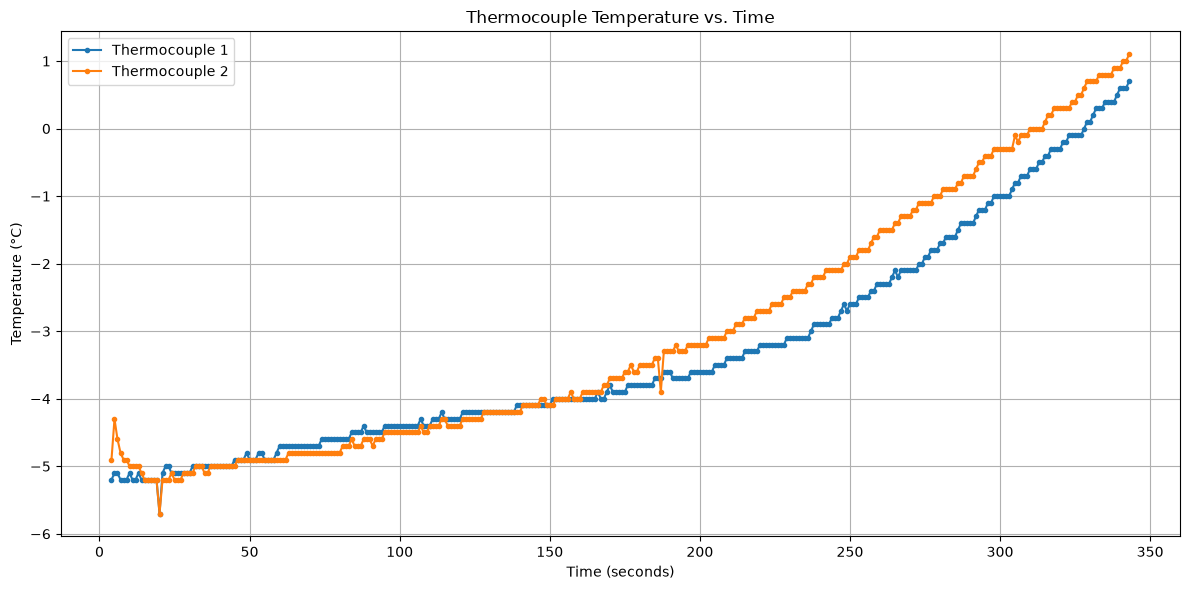

In [109]:

# SECTION 12: Plot temperature vs. time

import pandas as pd
import matplotlib.pyplot as plt

# Use manually corrected readings if available
if "edited_results_df" in globals():
    plot_df = edited_results_df.copy()
else:
    plot_df = results_df.copy()

# Convert readings to numeric values
plot_df["time_seconds"] = pd.to_numeric(
    plot_df["time_seconds"], errors="coerce"
)
plot_df["T1_temperature"] = pd.to_numeric(
    plot_df["T1_temperature"], errors="coerce"
)
plot_df["T2_temperature"] = pd.to_numeric(
    plot_df["T2_temperature"], errors="coerce"
)

plot_df = plot_df.sort_values("time_seconds")

plt.figure(figsize=(12, 6))

plt.plot(
    plot_df["time_seconds"],
    plot_df["T1_temperature"],
    marker="o",
    markersize=3,
    label="Thermocouple 1"
)

plt.plot(
    plot_df["time_seconds"],
    plot_df["T2_temperature"],
    marker="o",
    markersize=3,
    label="Thermocouple 2"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Temperature (°C)")
plt.title("Thermocouple Temperature vs. Time")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
